# Qudit Link Bench — walkthrough
**How many dimensions should a tactical quantum link use, and can it tell an attacker from a broken component?**

This notebook shows the circuits, reproduces the core result live, and loads the saved results of the longer experiments. See `README.md` for the full write-up and limitations.

## 1. The protocol as Qiskit circuits
A qudit of dimension d = 2ⁿ lives on n qubits. Basis Z is the computational basis; basis F is its Fourier transform. The two are mutually unbiased, which is the source of security.

Alice sends k=2 in the Fourier basis, Bob measures in the Fourier basis:


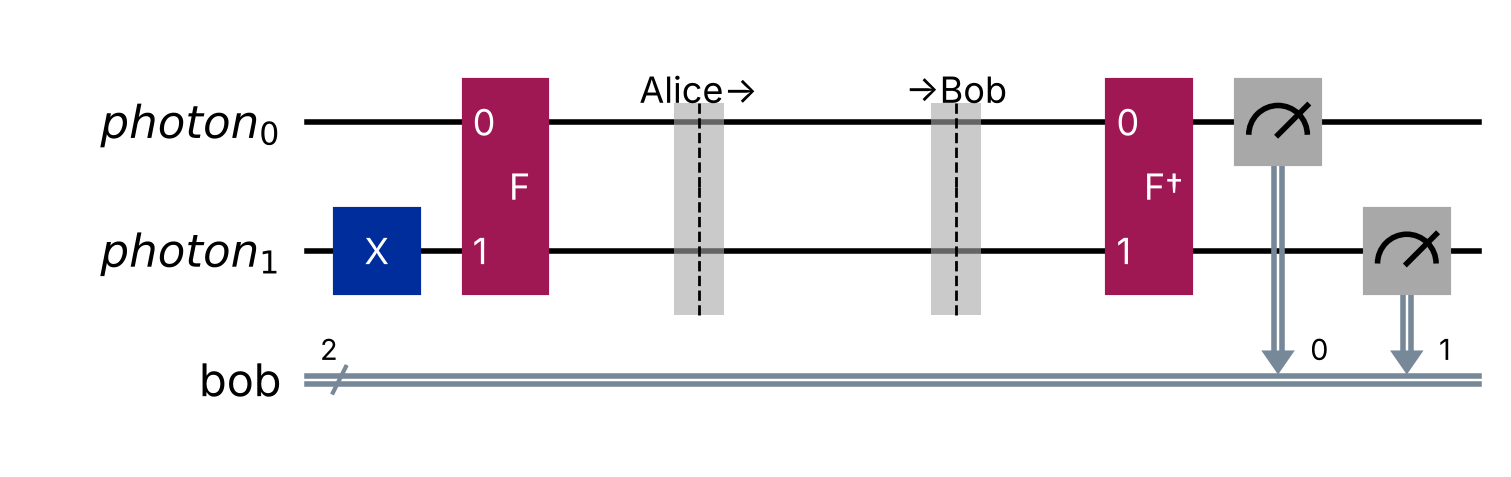

In [1]:
import numpy as np, json
from IPython.display import Image, display
from qudit_bb84 import QuditBB84, theory_qber_depol, theory_qber_ir, threshold_qber
from entanglement import witness_circuits, check_bound

q4 = QuditBB84(4, seed=1)
print('Alice sends k=2 in the Fourier basis, Bob measures in the Fourier basis:')
display(q4.circuit(2, 'F').draw('mpl', fold=-1))

An eavesdropper doing **intercept-resend** is a mid-circuit measurement followed by re-preparation in her guessed basis:

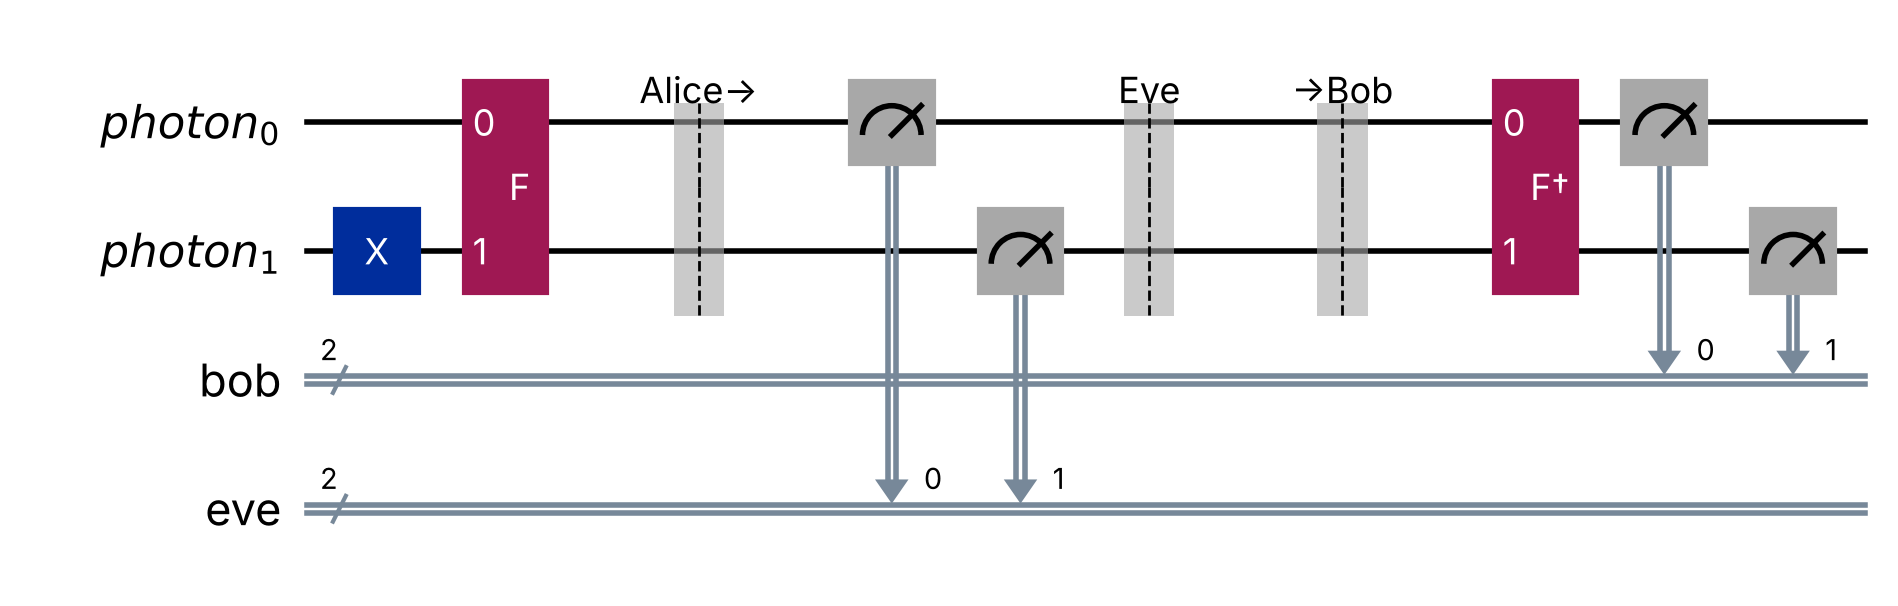

In [2]:
display(q4.circuit(2, 'F', eve_basis='Z').draw('mpl', fold=-1))

## 2. Live check against theory

In [3]:
for d in (2, 4, 8):
    sim = QuditBB84(d, seed=3)
    s = sim.run_session(3000, lam=0.10)
    e = sim.run_session(3000, f_eve=1.0)
    print(f"d={d}: QBER at λ=0.10  sim {(s['Q_Z']+s['Q_F'])/2:.3f} vs theory {theory_qber_depol(.1, d):.3f} | "
          f"full intercept-resend  sim {(e['Q_Z']+e['Q_F'])/2:.3f} vs theory {theory_qber_ir(1, d):.3f} | abort threshold {threshold_qber(d):.3f}")

d=2: QBER at λ=0.10  sim 0.056 vs theory 0.050 | full intercept-resend  sim 0.255 vs theory 0.250 | abort threshold 0.110
d=4: QBER at λ=0.10  sim 0.079 vs theory 0.075 | full intercept-resend  sim 0.386 vs theory 0.375 | abort threshold 0.189


d=8: QBER at λ=0.10  sim 0.093 vs theory 0.088 | full intercept-resend  sim 0.434 vs theory 0.438 | abort threshold 0.247


## 3. Experiment A — qubit vs qudit

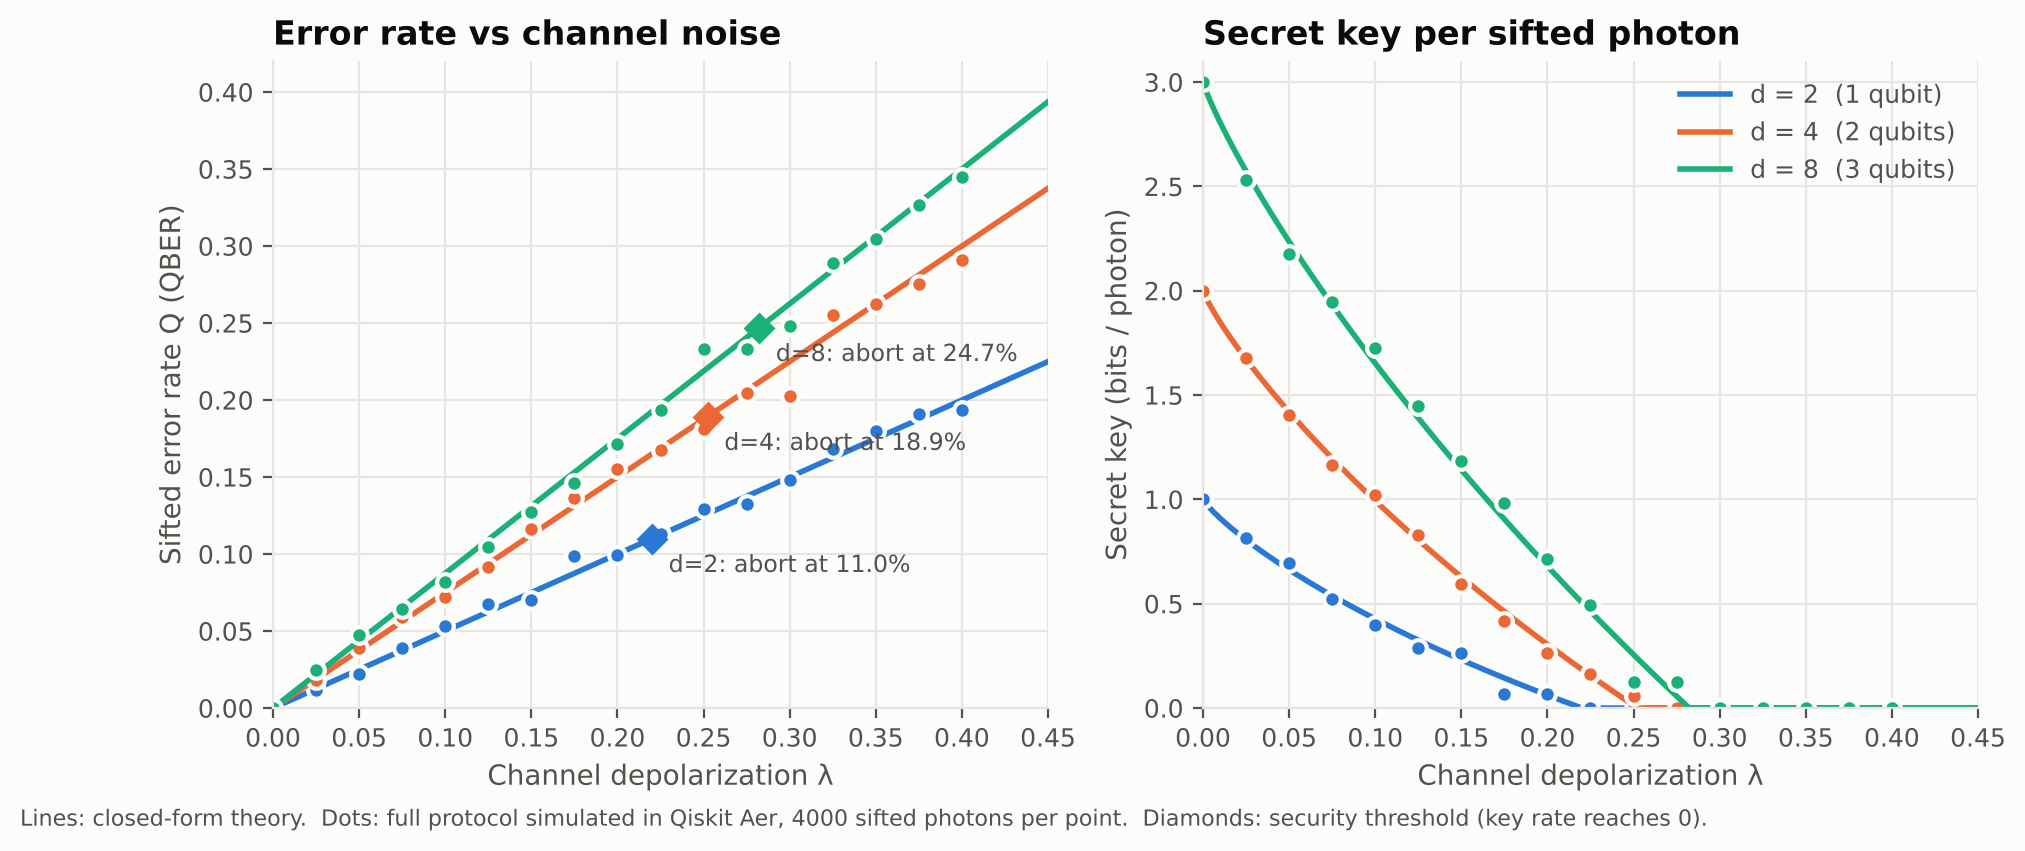

In [4]:
display(Image('figs/A_qubit_vs_qudit.png'))

## 4. Experiment B — component crosstalk budget
Crosstalk between adjacent modes only corrupts the Z basis. Per-basis accounting keeps far more key.

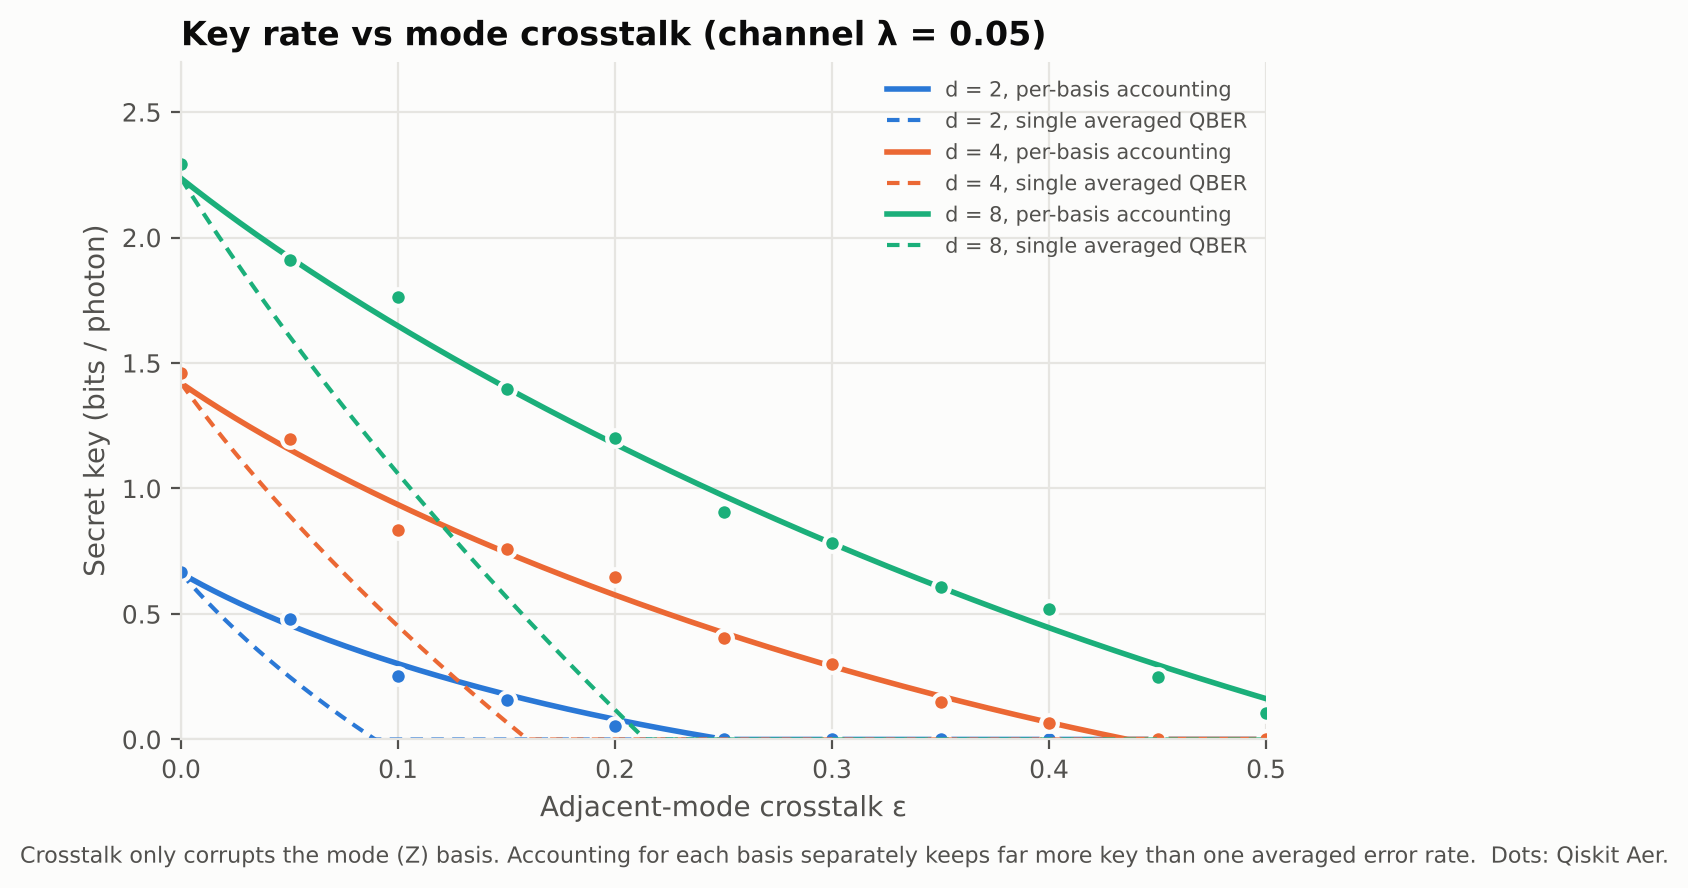

In [5]:
display(Image('figs/B_crosstalk_budget.png'))

## 5. Experiment C — link monitor: classical vs quantum kernel
The quantum-kernel SVM reaches parity with classical models once its bandwidth is tuned. Nothing can separate an eavesdropper from turbulence using error statistics alone: intercept-resend on a fraction f equals depolarizing noise λ = f/2 on sifted data.

three_class
   QBER rule (standard)               0.578 ± 0.009
   Physics rule (2 thresholds)        0.927 ± 0.022
   Logistic regression                0.964 ± 0.016
   Random forest                      0.953 ± 0.025
   MLP                                0.959 ± 0.019
   RBF-kernel SVM (classical, tuned)  0.959 ± 0.017
   Quantum-kernel SVM (untuned)       0.805 ± 0.037
   Quantum-kernel SVM (tuned)         0.949 ± 0.021
eve_vs_turbulence
   QBER rule (standard)               0.460 ± 0.015
   Physics rule (2 thresholds)        0.440 ± 0.060
   Logistic regression                0.497 ± 0.051
   Random forest                      0.457 ± 0.067
   MLP                                0.483 ± 0.061
   RBF-kernel SVM (classical, tuned)  0.515 ± 0.035
   Quantum-kernel SVM (untuned)       0.543 ± 0.061
   Quantum-kernel SVM (tuned)         0.517 ± 0.096


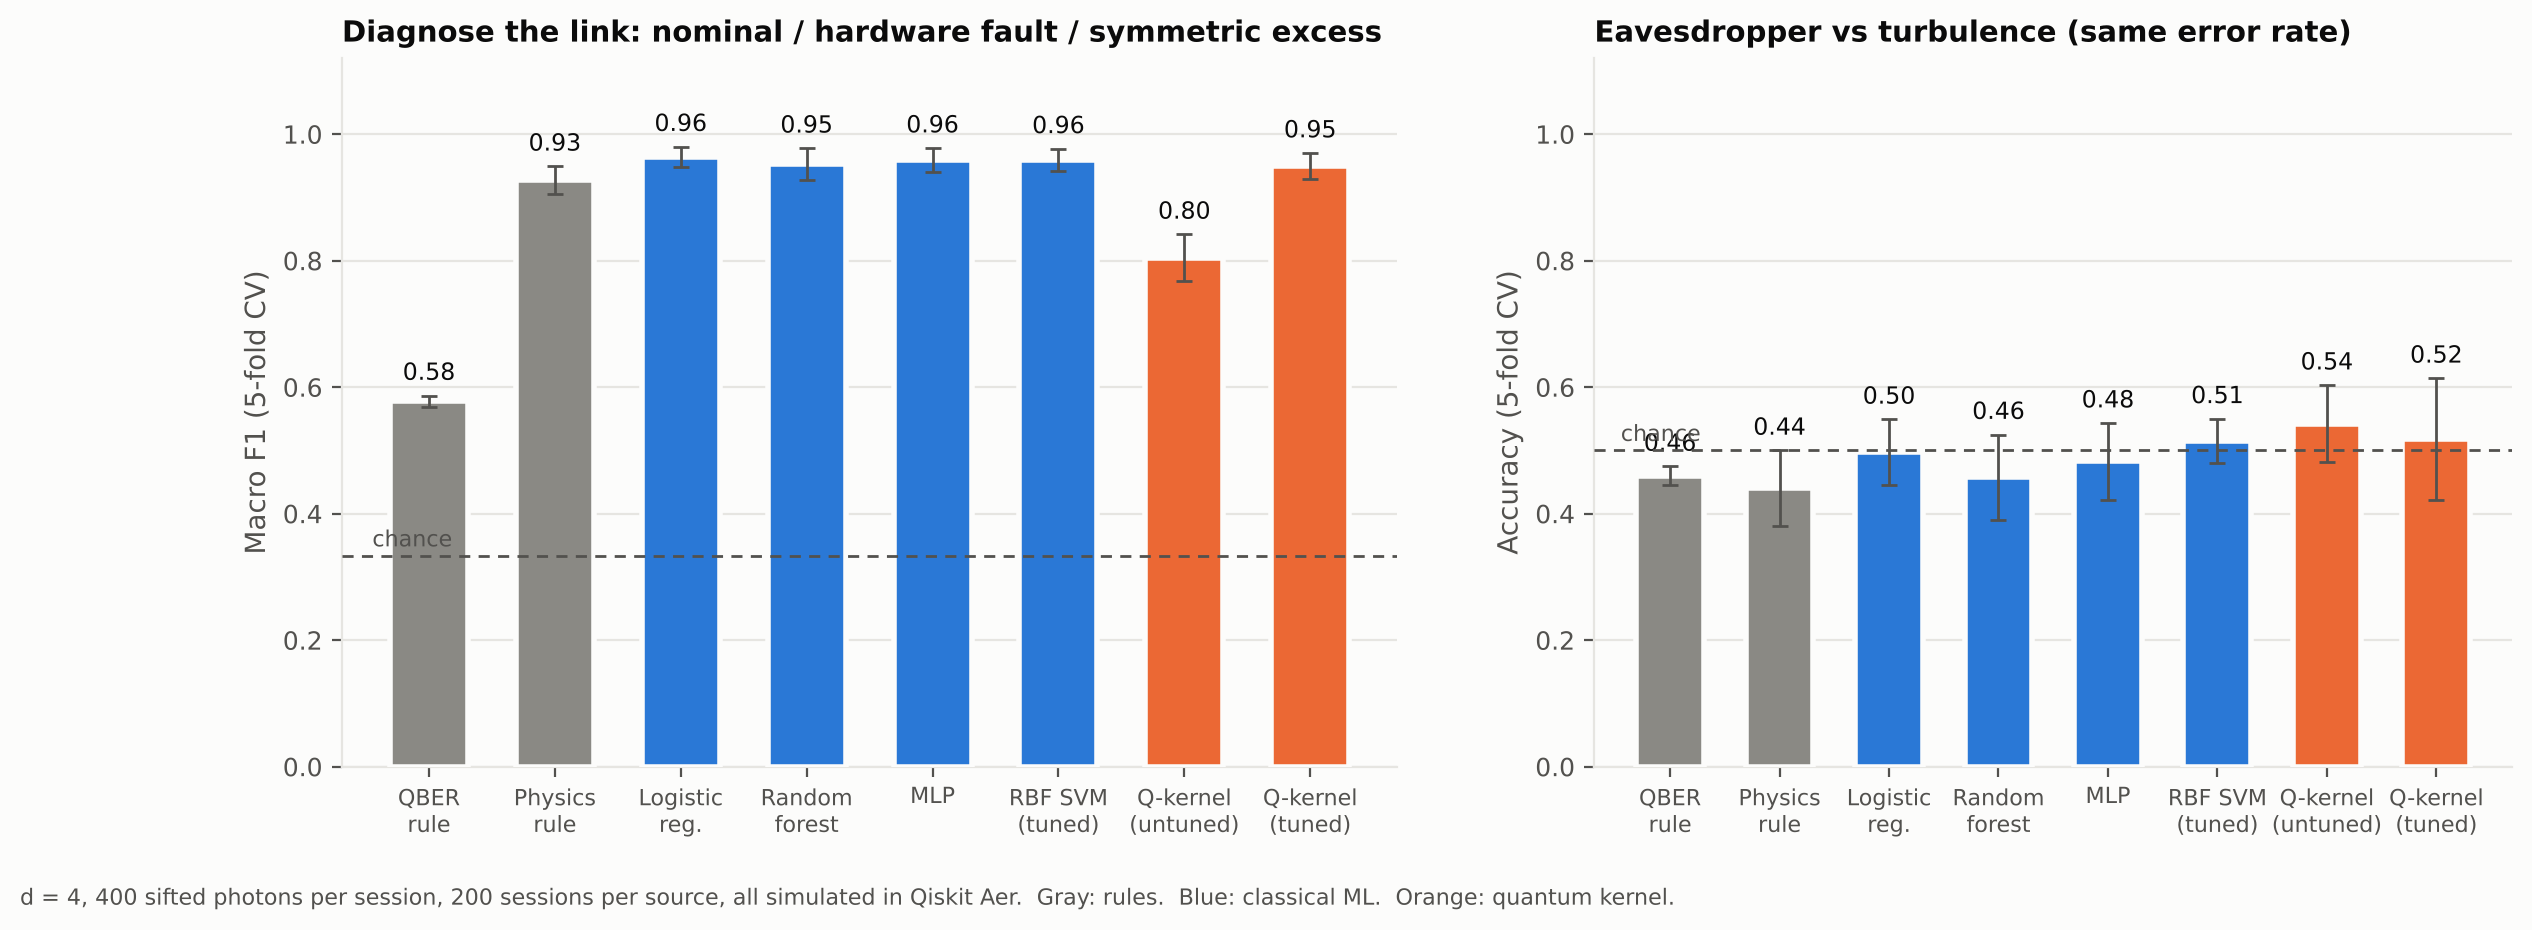

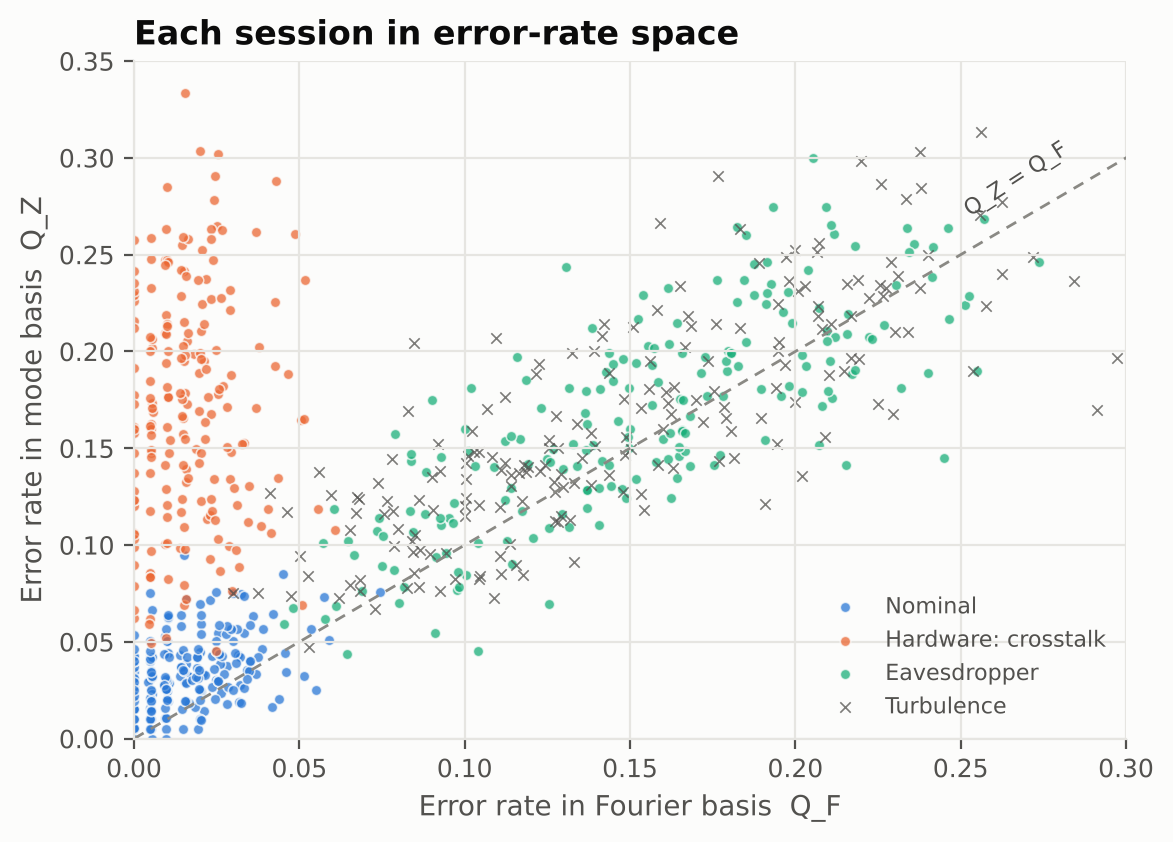

In [6]:
r = json.load(open('results/monitor.json'))
for task, key in [('three_class', 'f1'), ('eve_vs_turbulence', 'acc')]:
    print(task)
    for n, v in r[task].items():
        print(f"   {n.replace(chr(10), ' '):34s} {v[key]:.3f} ± {v[key + '_sd']:.3f}")
display(Image('figs/C_monitor.png')); display(Image('figs/C_feature_space.png'))

## 6. Experiment D — certifying high-dimensional entanglement with two settings
F ≥ P_Z + P_F − 1 is an operator inequality (largest eigenvalue below should be ≈ 0). F > k/d certifies Schmidt number ≥ k+1.

{2: 0.0, 4: 0.0, 8: 0.0}


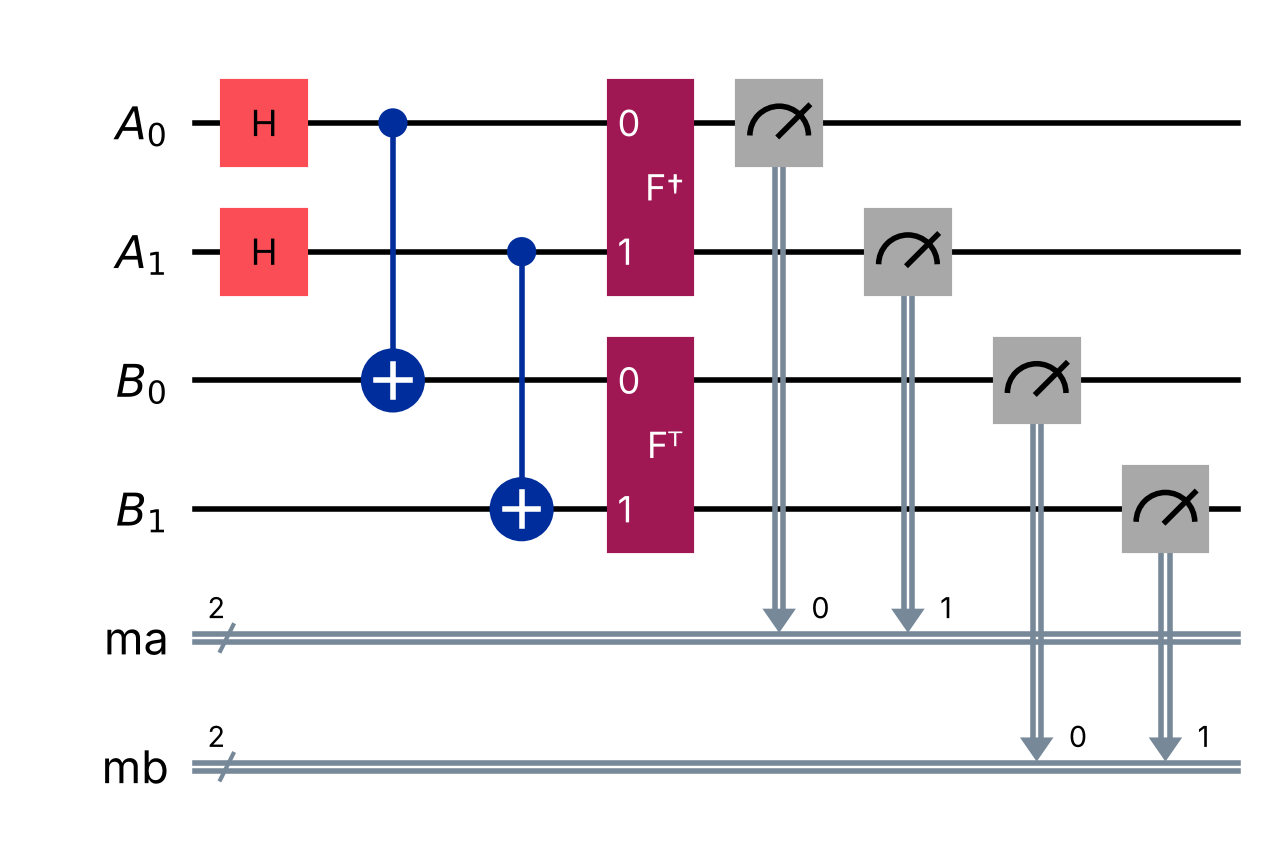

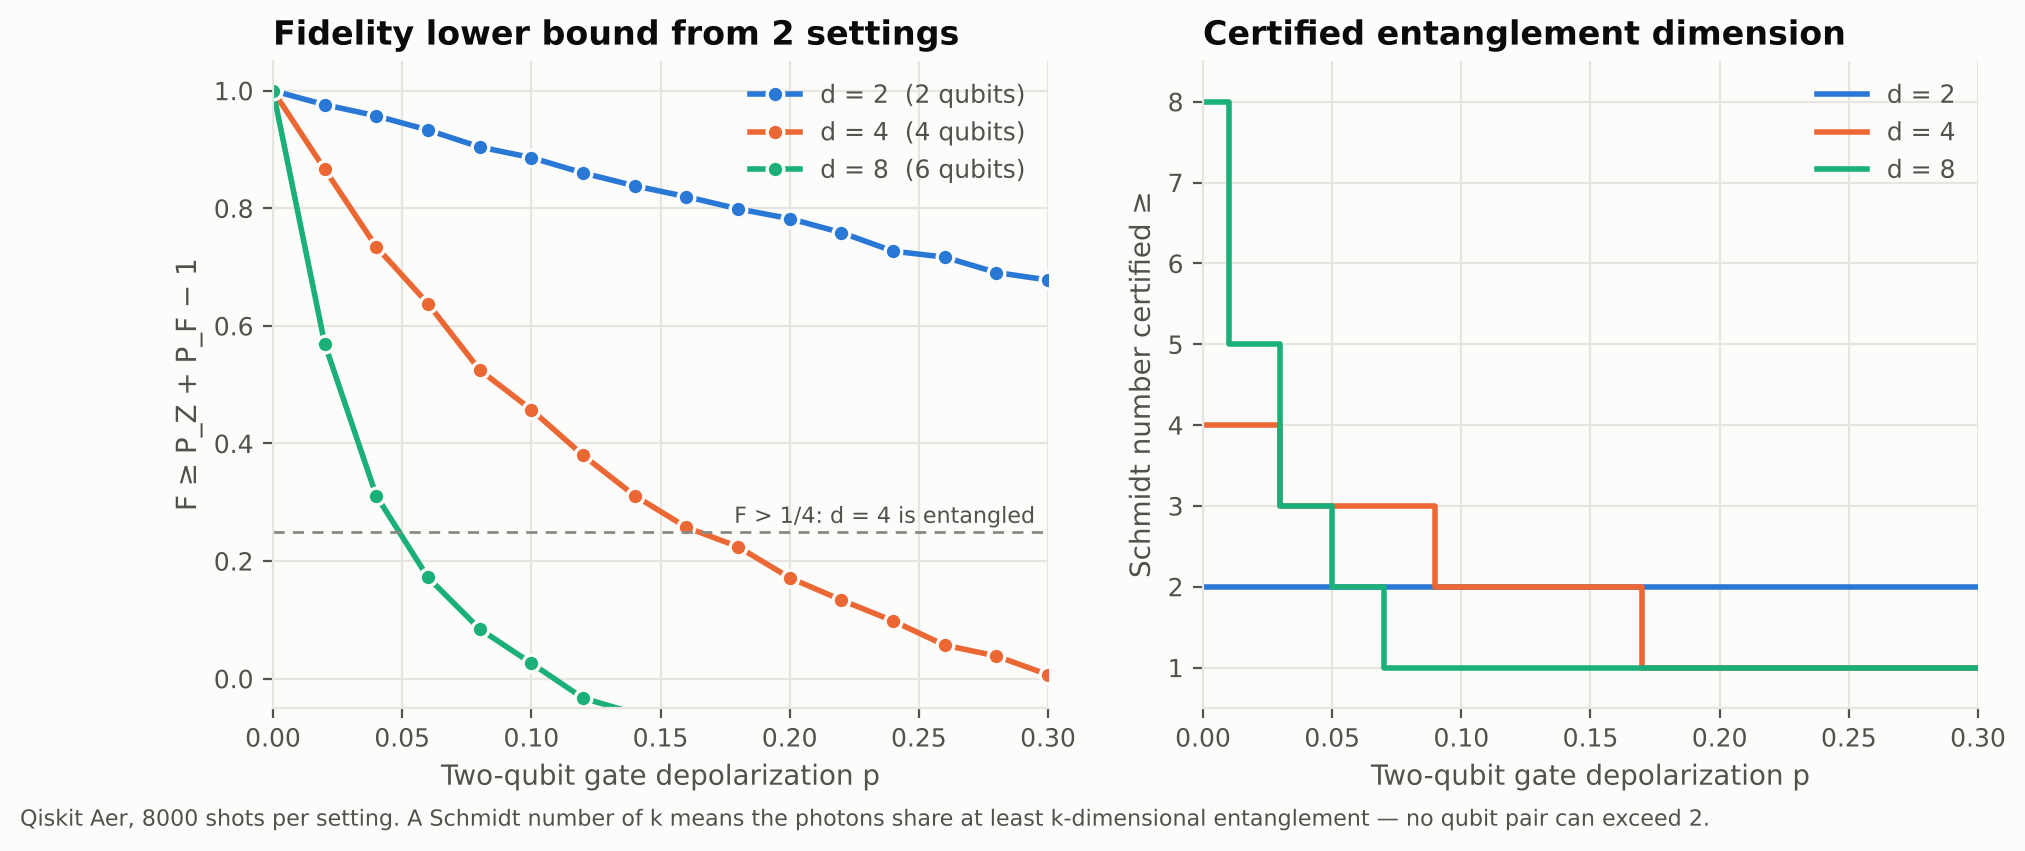

In [7]:
print({d: round(check_bound(d), 12) for d in (2, 4, 8)})
display(witness_circuits(4)['FF'].draw('mpl', fold=-1))
display(Image('figs/D_entanglement_sim.png'))

## 7. Real hardware: IBM Kingston
The processor itself acts as the channel. Raw job: 92 circuits, 33 s of QPU time. Layers: Torino noise-model prediction, raw, + readout correction, DD + twirling + readout correction. Raw data certify ≥ 6-dimensional entanglement (F = 0.727 ± 0.007 > 5/8, 13.6σ).

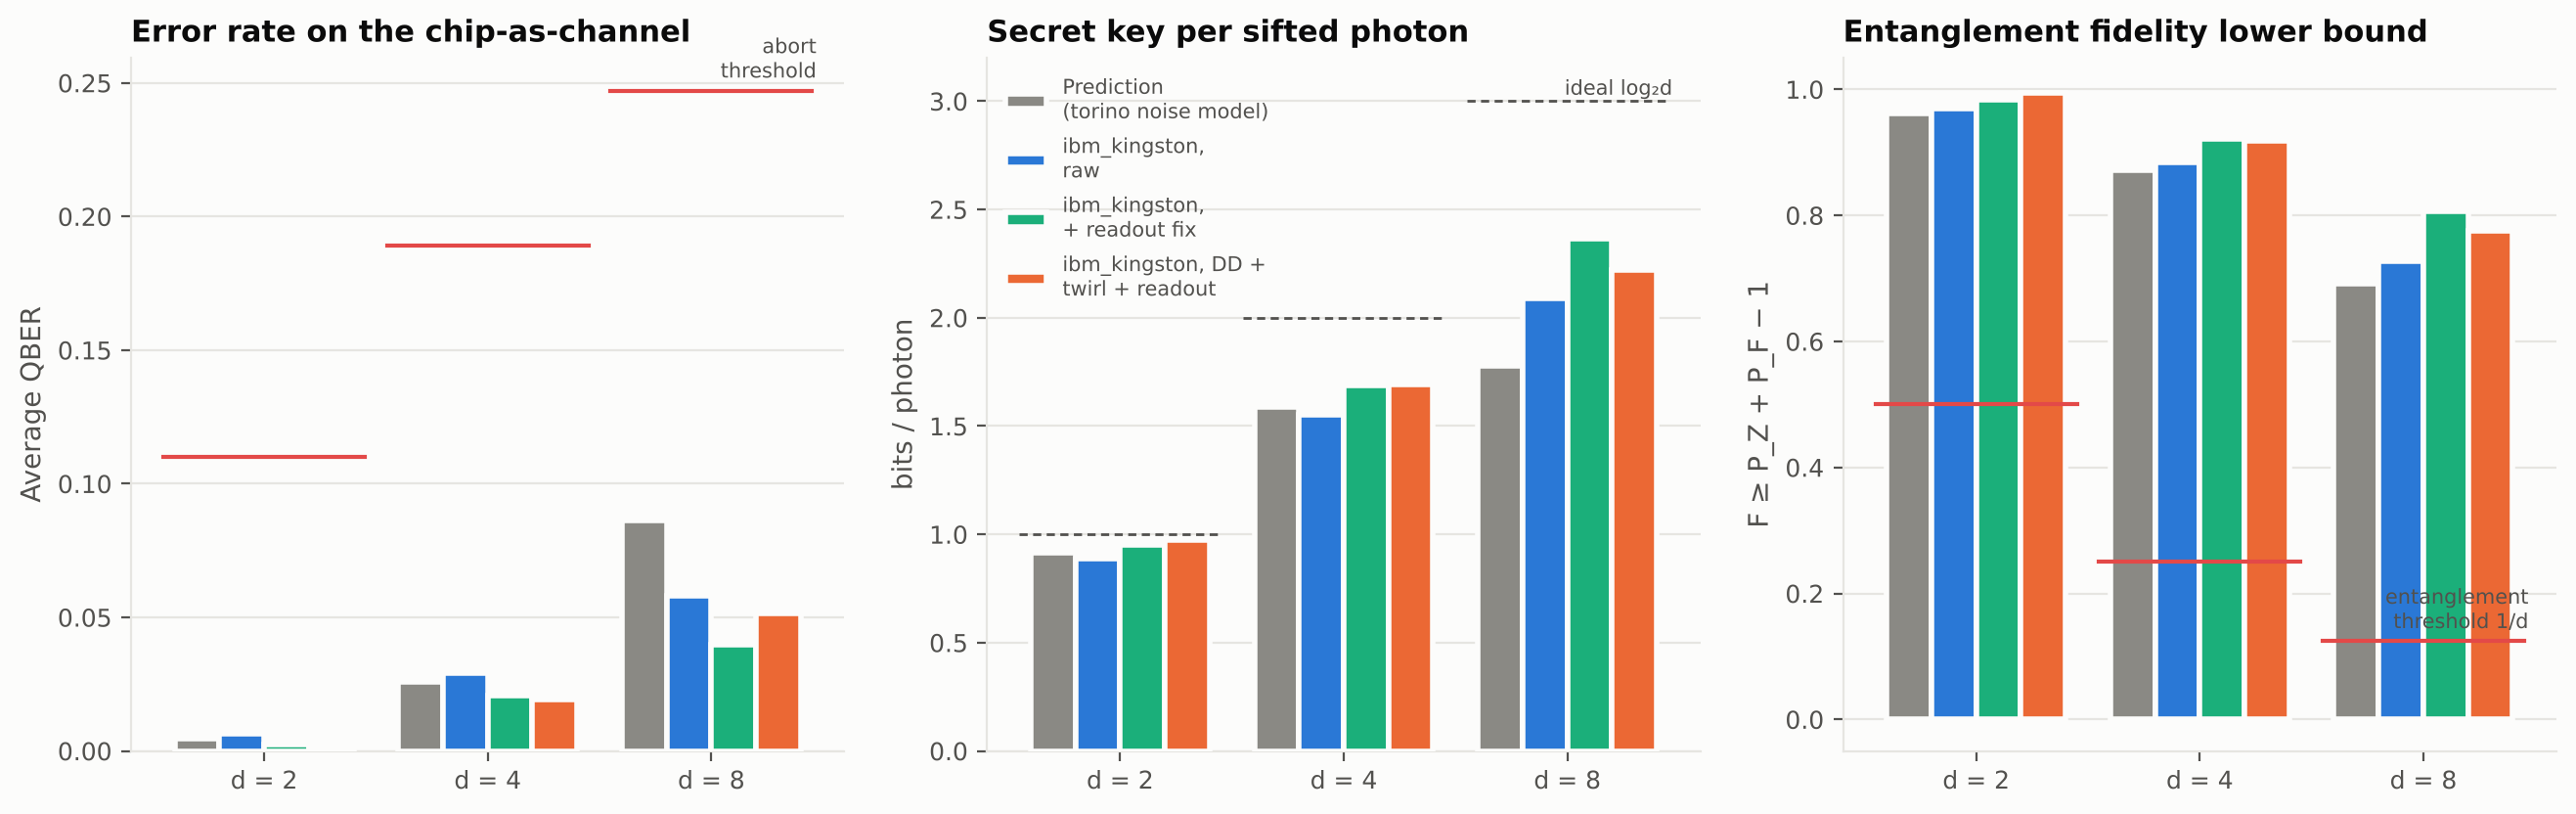

{
 "Prediction (torino noise model)": {
  "2": [
   0.962,
   2
  ],
  "4": [
   0.871,
   4
  ],
  "8": [
   0.692,
   6
  ]
 },
 "ibm_kingston, raw": {
  "2": [
   0.969,
   2
  ],
  "4": [
   0.885,
   4
  ],
  "8": [
   0.727,
   6
  ]
 },
 "ibm_kingston, + readout fix": {
  "2": [
   0.984,
   2
  ],
  "4": [
   0.922,
   4
  ],
  "8": [
   0.806,
   7
  ]
 },
 "ibm_kingston, DD + twirl + readout": {
  "2": [
   0.994,
   2
  ],
  "4": [
   0.919,
   4
  ],
  "8": [
   0.775,
   7
  ]
 }
}


In [8]:
display(Image('figs/E_hardware.png'))
print(json.dumps({k: {d: (round(v['witness'][d]['fidelity_lower_bound'], 3), v['witness'][d]['certified_schmidt_number']) for d in v['witness']} for k, v in json.load(open('results/hardware_summary.json')).items()}, indent=1))

## 8. What these results cannot support
See README §6: the chip is not a photonic link; key rates are asymptotic upper bounds; qudit gate cost is an artifact of qubit hardware; monitor data are synthetic; no quantum advantage is claimed; the witness trusts its measurements; fake-backend models are optimistic.